In [3]:
#importo las librerias y defino las funciones

import os
import numpy as np
import cv2
import joblib

from matplotlib import pyplot as plt
import matplotlib 

# Local descriptors
from skimage.feature import hog
from skimage import exposure
from skimage import feature

from time import time
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import precision_score, recall_score
from sklearn.decomposition import PCA
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import MinMaxScaler

import warnings
warnings.filterwarnings("ignore")
#divide las imagenes en unca cuadricula de celdas, calcula los patrones binarios locales y concatena los histrogramas
def lbphist(gray, ncellsx, ncellsy, width, height, type):
    pxpercellx = int(width/ncellsx)
    pxpercelly = int(height/ncellsy)
    ofx = int((width - int(pxpercellx)*ncellsx)/2)
    ofy = int((height - int(pxpercelly)*ncellsy)/2)
   
    LBPu_hist = []
    for i in range(0, ncellsy):
        for j in range(0, ncellsx):
            roi = gray[ofy+i*pxpercelly:ofy+(i+1)*pxpercelly, ofx+j*pxpercellx:ofx+(j+1)*pxpercellx]
            lbpimg = feature.local_binary_pattern(roi, 8, 1, method=type)
            n_bins = 59 if type == "nri_uniform" else int(lbpimg.max()) + 1
            feath, bins = np.histogram(lbpimg, density=False, bins=n_bins, range=(0, n_bins))
            LBPu_hist = np.concatenate([LBPu_hist, feath])
            
    return LBPu_hist

#extrae los  histogramas de gradientes orientados para cada rostro captura la forma y los bordes de las caras
def GetHOG(X, ncellsx, ncellsy, width, height):
    Xhog = []
    for i in range(len(X)):
        gray = X[i].reshape(height, width)
        feat_hog, _ = hog(gray, orientations=8, pixels_per_cell=(height/ncellsy, width/ncellsx),
                          cells_per_block=(1, 1), visualize=True, block_norm='L1')
        Xhog.append(feat_hog)
    return Xhog
#hace lo mismo que lbphist       
def GetLBP(X, ncellsx, ncellsy, width, height, lbptype):
    Xlbp = []
    for i in range(len(X)):
        gray = X[i].reshape(height, width)
        feat_lbp = lbphist(gray, ncellsx, ncellsy, width, height, lbptype) 
        Xlbp.append(feat_lbp)
    return Xlbp

#normaliza los datos entre 0 y 1 y busca automáticamente los hiperparámetros con validación cruzada y como hay desbalanceos en lass muestras lo balanceamos
def GetPredictions(X_train, X_test, y_train, y_test):
    scaler = MinMaxScaler()
    train_X = scaler.fit_transform(X_train)
    test_X = scaler.transform(X_test)

    parameters = {'C': [1e2, 1e3, 5e3],
                  'gamma': [0.0001, 0.001, 0.005, 0.01]}
    clf = GridSearchCV(SVC(kernel='rbf', class_weight='balanced'), parameters, cv=5)
    clf = clf.fit(train_X, y_train)
    y_pred = clf.predict(test_X)
    return y_pred, y_test
#hace lo mismo que la anterior pero activando probability para devolver tambien las probabilidades de pertenencia a cada emoción
def GetPredictionsandProbs(X_train, X_test, y_train, y_test):
    scaler = MinMaxScaler()
    train_X = scaler.fit_transform(X_train)
    test_X = scaler.transform(X_test)

    parameters = {'C': [1e2, 1e3, 5e3],
                  'gamma': [0.0001, 0.001, 0.005, 0.01]}
    clf = GridSearchCV(SVC(kernel='rbf', class_weight='balanced', probability=True), parameters, cv=5)
    clf = clf.fit(train_X, y_train)
    y_pred = clf.predict(test_X)
    ytrain_prob = clf.predict_proba(train_X)
    ytest_prob = clf.predict_proba(test_X)
    return y_pred, y_test, ytrain_prob, ytest_prob

Loading dataset...
Dataset info:
# samples: 3436
# features: 2304
# classes: 7
classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
samples per class: 500, 436, 500, 500, 500, 500, 500


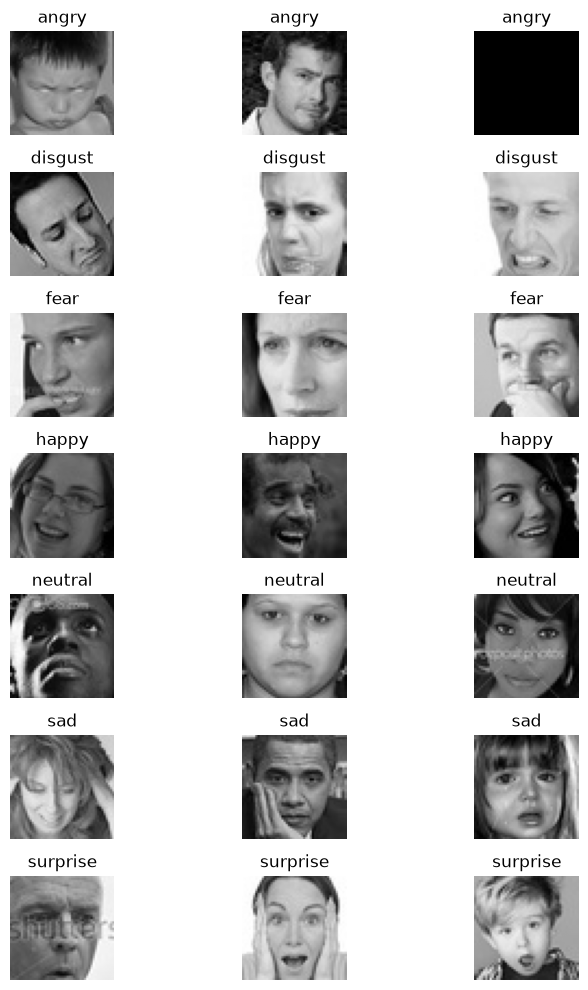

In [4]:
##esta funcion recorre cada subcarpeta del dataseet en orden alfabetico
def LoadDataset(folder, ext, max_por_clase=500):

    nclasses = 0
    nsamples = 0
    nperclass = []
    classlabels = []
    X = []
    Y = []

    for class_name in sorted(os.listdir(folder)):
        class_folder = os.path.join(folder, class_name)
        if not os.path.isdir(class_folder):
            continue

        classlabels.append(class_name)
        nsamples_class = 0
#carga las imagenes en gris  y las redimensiono a 48x48 y los aplana y lo limito a 500 para no desequilibrar
        for file in sorted(os.listdir(class_folder)):
            if file.lower().endswith(ext):
                img_path = os.path.join(class_folder, file)
                img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
                if img is not None:
                    img = cv2.resize(img, (48, 48))
                    X.append(img.flatten())
                    Y.append(nclasses)
                    nsamples_class += 1
                    nsamples += 1
                    if nsamples_class >= max_por_clase:
                        break

        nperclass.append(nsamples_class)
        nclasses += 1
#X contiene todos los rostros tamaño n_samples x 2304) y en Y se guarda la etiqueta númerica correspondiente 
    height, width = 48, 48
    return X, Y, nsamples, classlabels, nperclass, classlabels, width, height #que guarda aqui?

folder = r"datasetemocionesdistintos\train"

print('Loading dataset...')
X, Y, nsamples, class_name, nperclass, classlabels, width, height = LoadDataset(folder, '.jpg', max_por_clase=500)

X = np.array(X, dtype='float32')
Y = np.array(Y, dtype='float64')

#me imprime el total de muestras cargadas, dimension de ada vector , numero de clases, nombres e imágenes de cada emoción

n_samples, n_features = X.shape
class_names = np.array(classlabels)
n_classes = class_names.shape[0]

print("Dataset info:")
print("# samples: %d" % n_samples)
print("# features: %d" % n_features)
print("# classes: %d" % n_classes)
print("classes: %s" % classlabels)
print("samples per class: %s" % str(nperclass)[1:-1])

# Muestra 3 imágenes por cada emoción con matplotlib
dpi = matplotlib.rcParams['figure.dpi']
nims2show = 3
fig = plt.figure(figsize=(8, 10))
for nc in range(n_classes):
    nimgs = 0
    i = 0
    while i < nims2show and nimgs < n_samples:
        if Y[nimgs] == nc:
            gray = X[nimgs].reshape(height, width)
            ax = fig.add_subplot(n_classes, nims2show, nc * nims2show + i + 1)
            ax.set_title(classlabels[nc])
            ax.axis('off')
            plt.imshow(gray, cmap='gray', vmin=0, vmax=255) 
            i += 1 
        nimgs += 1
plt.tight_layout()
plt.show()

In [3]:
#celda de extraccion de descriptores y experimentación comparativa
# Para 48x48 píxeles, una rejilla 6x6 (celdas de 8x8 px) funciona aún mejor que 4x4
#calculo el vector de HOG dividiendo cada cara de 48 en 6 rejillas de 6x6 celdas y con lbp de 4x4v
Xhog = np.array(GetHOG(X, 6, 6, width, height), dtype='float32')
Xlbp = np.array(GetLBP(X, 4, 4, width, height, "nri_uniform"), dtype='float32')

kfold = 5
#Divide el dataset en 5 particiones manteniendo la misma proporcion de cada emoción en cada una. En cada iteración entrena con el 80% y valida con el 20%
skf = StratifiedKFold(n_splits=kfold, random_state=4, shuffle=True)

precs_px_knn, recs_px_knn = [], []
precs_pca_knn, recs_pca_knn = [], []
precs_pca_svm, recs_pca_svm = [], []
precs_hog_svm, recs_hog_svm = [], []
precs_lbp_svm, recs_lbp_svm = [], []
precs_stk_svm, recs_stk_svm = [], []

knn = 5
fold = 1

for train_index, test_index in skf.split(X, Y):
    print("\nFold %d" % fold)
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = Y[train_index], Y[test_index]
    Xhog_train, Xhog_test = Xhog[train_index], Xhog[test_index]
    Xlbp_train, Xlbp_test = Xlbp[train_index], Xlbp[test_index]
    
    # 1. Píxeles + KNN. Mira el nivel de gris y coge las 5 caras mas parecidas
    model_px = KNeighborsClassifier(n_neighbors=knn).fit(X_train, y_train)
    y_pred = model_px.predict(X_test)
    precs_px_knn.append(precision_score(y_test, y_pred, average='weighted'))
    recs_px_knn.append(recall_score(y_test, y_pred, average='weighted'))
    
    # PCA 95%. 
    pca_95 = PCA(.95).fit(X_train)
    X_train_pca_95 = pca_95.transform(X_train)
    X_test_pca_95 = pca_95.transform(X_test)
    
    # 2. PCA + KNN Se queda solo con los pixeles que explican el 95% de la cara y coge los 5 vecinos mas cercanos
    model_pca_95 = KNeighborsClassifier(n_neighbors=knn).fit(X_train_pca_95, y_train)
    y_pred = model_pca_95.predict(X_test_pca_95)
    precs_pca_knn.append(precision_score(y_test, y_pred, average='weighted'))
    recs_pca_knn.append(recall_score(y_test, y_pred, average='weighted'))
    
    # 3. PCA + SVM. Usa las mismas componentes pero entrenando una Maquina de Vectores de Soporte, dibujando las fronteras y cogiendo a la que se parezca
    y_pred, _ = GetPredictions(X_train_pca_95, X_test_pca_95, y_train, y_test)
    precs_pca_svm.append(precision_score(y_test, y_pred, average='weighted'))
    recs_pca_svm.append(recall_score(y_test, y_pred, average='weighted'))
        
    # 4. HOG + SVM Divide la imagen en 6x6 celdas mirando a donde apuntan los bordes y contornos de la cara, será el mejor 
    y_pred, _ = GetPredictions(Xhog_train, Xhog_test, y_train, y_test)
    precs_hog_svm.append(precision_score(y_test, y_pred, average='weighted'))
    recs_hog_svm.append(recall_score(y_test, y_pred, average='weighted'))
    if fold == 1:
        print("\nHOG+SVM Report (Fold 1):")
        print(classification_report(y_test, y_pred, target_names=class_names))
        print("Confusion matrix:\n", confusion_matrix(y_test, y_pred, labels=range(n_classes)))
    
    # 5. LBP + SVM divide la cara en 4x4 celdas y compara los 8 vecinos para medir la textura con como se arruga la cara
    y_pred, _ = GetPredictions(Xlbp_train, Xlbp_test, y_train, y_test)
    precs_lbp_svm.append(precision_score(y_test, y_pred, average='weighted'))
    recs_lbp_svm.append(recall_score(y_test, y_pred, average='weighted'))

    # 6. Ensemble / Stacking (corregido con hstack para multiclase) Combina PCA,HOG,LBPC y entrena un cuarto clasificador que decide la emoción a parte de la opinión de los 3
    _, _, pca95_train_prob, pca95_test_prob = GetPredictionsandProbs(X_train_pca_95, X_test_pca_95, y_train, y_test)
    _, _, hog_train_prob, hog_test_prob = GetPredictionsandProbs(Xhog_train, Xhog_test, y_train, y_test)
    _, _, lbp_train_prob, lbp_test_prob = GetPredictionsandProbs(Xlbp_train, Xlbp_test, y_train, y_test)
    
    X_stk_train = np.hstack((pca95_train_prob, hog_train_prob, lbp_train_prob))
    X_stk_test = np.hstack((pca95_test_prob, hog_test_prob, lbp_test_prob))
    y_pred, _ = GetPredictions(X_stk_train, X_stk_test, y_train, y_test)
        
    precs_stk_svm.append(precision_score(y_test, y_pred, average='weighted'))
    recs_stk_svm.append(recall_score(y_test, y_pred, average='weighted'))
    if fold == 1:
        print("\nEnsemble/Stacking de la primera carpeta:")
        print(classification_report(y_test, y_pred, target_names=class_names))
        print("Confusion matrix:\n", confusion_matrix(y_test, y_pred, labels=range(n_classes)))
    
    fold += 1

print("\n PARAMETROS DE K-FOLD ")
print("PX+KNN   Precision Media: %0.3f, Sensibilidad Media: %0.3f" % (np.mean(precs_px_knn), np.mean(recs_px_knn))) 
print("PCA+KNN  Precision Media: %0.3f, Sensibilidad Media: %0.3f" % (np.mean(precs_pca_knn), np.mean(recs_pca_knn))) 
print("PCA+SVM  Precision Media: %0.3f, Sensibilidad Media: %0.3f" % (np.mean(precs_pca_svm), np.mean(recs_pca_svm))) 
print("HOG+SVM  Precision Media: %0.3f, Sensibilidad Media: %0.3f" % (np.mean(precs_hog_svm), np.mean(recs_hog_svm))) 
print("LBP+SVM  Precision Media: %0.3f, Sensibilidad Media: %0.3f" % (np.mean(precs_lbp_svm), np.mean(recs_lbp_svm))) 
print("Ensemble Precision Media: %0.3f, Sensibilidad Media: %0.3f" % (np.mean(precs_stk_svm), np.mean(recs_stk_svm)))


Fold 1

HOG+SVM Report (Fold 1):
              precision    recall  f1-score   support

       angry       0.24      0.24      0.24       100
     disgust       0.41      0.64      0.50        88
        fear       0.27      0.28      0.28       100
       happy       0.40      0.44      0.42       100
     neutral       0.28      0.27      0.27       100
         sad       0.22      0.14      0.17       100
    surprise       0.50      0.39      0.44       100

    accuracy                           0.34       688
   macro avg       0.33      0.34      0.33       688
weighted avg       0.33      0.34      0.33       688

Confusion matrix:
 [[24 19 15 16  8 13  5]
 [ 8 56  3  8  4  5  4]
 [17 10 28  9 19  5 12]
 [11  8 11 44  6 11  9]
 [19 14 17 10 27 10  3]
 [14 14 18 12 22 14  6]
 [ 6 15 10 12 12  6 39]]

Ensemble/Stacking de la primera carpeta:
              precision    recall  f1-score   support

       angry       0.27      0.29      0.28       100
     disgust       0.51      0

In [4]:
# Entrenamos el clasificador HOG+SVM con el 100% de las muestras para usarlo en tiempo real
#escala los valores de hog  y esa escalada lo hace a cada fotograma
scaler_final = MinMaxScaler()
Xhog_scaled = scaler_final.fit_transform(Xhog)
#encuentra los mejores parámetros del SVM activando el porcentaje de cada emoción y el balanceo prueba las 3x4 combinaciones
parameters = {'C': [1e2, 1e3, 5e3], 'gamma': [0.0001, 0.001, 0.005, 0.01]}
clf_final = GridSearchCV(SVC(kernel='rbf', class_weight='balanced', probability=True), parameters, cv=5)
clf_final.fit(Xhog_scaled, Y)

print("Mejor modelo final encontrado:", clf_final.best_estimator_)
#se guarda el mejor modelo
# Guardamos el scaler, el modelo y las etiquetas en un solo archivo
paquete_modelo = {
    'scaler': scaler_final,
    'modelo': clf_final.best_estimator_,
    'clases': classlabels,
    'ncellsx': 6,
    'ncellsy': 6,
    'width': width,
    'height': height
}

joblib.dump(paquete_modelo, 'modelo_emociones_hog.pkl')
print("Guardado con éxito en 'modelo_emociones_hog.pkl'")

Mejor modelo final encontrado: SVC(C=100.0, class_weight='balanced', gamma=0.0001, probability=True)
Guardado con éxito en 'modelo_emociones_hog.pkl'


In [2]:
import os
import time
import math
import random
import urllib.request
import cv2
import joblib
import numpy as np
import mediapipe as mp
from skimage.feature import hog

if not os.path.exists("face_landmarker.task"):
    url = "https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task"
    urllib.request.urlretrieve(url, "face_landmarker.task")

# 1. Cargar tu modelo entrenado (CK+48)
paquete = joblib.load('modelo_emociones_hog.pkl')
scaler = paquete['scaler']
modelo = paquete['modelo']
clases = paquete['clases']
ncellsx = paquete['ncellsx']
ncellsy = paquete['ncellsy']
width = paquete['width']
height = paquete['height']

print("Modelo cargado correctamente. Clases:", clases)

# Normalizar nombres de clases
MAPA_EMOCION = {
    'angry': 'enfado', 'anger': 'enfado',
    'sad': 'triste', 'sadness': 'triste',
    'happy': 'feliz',
    'surprise': 'sorpresa',
    'fear': 'miedo',
    'disgust': 'asco',
    'neutral': 'neutral'
}

# Colores de los 468 landmarks y barras según cada emoción (en formato BGR)
COLORES_PUNTOS = {
    'enfado':   (0, 0, 255),     # Rojo
    'triste':   (255, 190, 50),  # Azul celeste
    'feliz':    (0, 230, 255),   # Dorado
    'sorpresa': (255, 255, 0),   # Cian
    'miedo':    (220, 0, 220),   # Morado
    'asco':     (50, 255, 50),   # Verde tóxico
    'neutral':  (0, 255, 120)    # Verde escáner
}

# Inicializar partículas para las animaciones
lluvia = [[random.randint(0, 640), random.randint(0, 480), random.randint(10, 20)] for _ in range(90)]
fuego = [[random.randint(0, 640), random.randint(350, 480), random.randint(8, 22)] for _ in range(80)]
confeti = [[random.randint(0, 640), random.randint(0, 480),
            (random.randint(50, 255), random.randint(50, 255), random.randint(50, 255))] for _ in range(70)]
burbujas = [[random.randint(0, 640), random.randint(0, 480), random.randint(6, 18), random.uniform(0, 6.28)] for _ in range(45)]

def dibujar_efectos(frame, estado, face_landmarks, w_img, h_img):
    overlay = frame.copy()

    if estado == 'triste':
        # 1. TRISTE: Tinte azul frío + gotas de lluvia cayendo
        cv2.rectangle(overlay, (0, 0), (w_img, h_img), (180, 90, 20), -1) #pinta de azul oscuro
        frame = cv2.addWeighted(overlay, 0.22, frame, 0.78, 0) #lo añade a mi cara yo 78 22 imagen original
        for gota in lluvia:
            gota[1] += gota[2] #baja la gota
            gota[0] -= 2 #se mueve para al lado la gota
            if gota[1] > h_img: #si se sale se recicla
                gota[0] = random.randint(0, w_img)
                gota[1] = 0
            cv2.line(frame, (gota[0], gota[1]), (gota[0] - 3, gota[1] + 15), (255, 200, 120), 2) #gotas de azul claro y grosor 2

    elif estado == 'enfado':
        # 2. ENFADO: Tinte rojo + llamas subiendo desde abajo
        cv2.rectangle(overlay, (0, 0), (w_img, h_img), (0, 0, 220), -1)
        frame = cv2.addWeighted(overlay, 0.25, frame, 0.75, 0)
        for llama in fuego:
            llama[1] -= random.randint(8, 16)
            llama[0] += random.randint(-4, 4)
            llama[2] = max(2, llama[2] - 1)
            if llama[1] < h_img // 2 or llama[2] <= 2:
                llama[0] = random.randint(0, w_img)
                llama[1] = h_img
                llama[2] = random.randint(12, 26)
            color_llama = (0, random.randint(60, 220), 255)
            cv2.circle(frame, (llama[0], llama[1]), llama[2], color_llama, -1)

    elif estado == 'feliz':
        # 3. FELIZ: Tinte cálido + confeti multicolor cayendo
        cv2.rectangle(overlay, (0, 0), (w_img, h_img), (0, 215, 255), -1)
        frame = cv2.addWeighted(overlay, 0.15, frame, 0.85, 0)
        for c in confeti:
            c[1] += random.randint(5, 11)
            c[0] += random.randint(-3, 3)
            if c[1] > h_img:
                c[0] = random.randint(0, w_img)
                c[1] = 0
            cv2.rectangle(frame, (c[0], c[1]), (c[0] + 8, c[1] + 8), c[2], -1)

    elif estado == 'sorpresa':
        # 4. SORPRESA: Destello cian + ondas expansivas desde la nariz
        cv2.rectangle(overlay, (0, 0), (w_img, h_img), (255, 200, 0), -1)
        frame = cv2.addWeighted(overlay, 0.18, frame, 0.82, 0)
        nariz = face_landmarks[1]
        cx, cy = int(nariz.x * w_img), int(nariz.y * h_img)
        radio1 = int((time.time() * 250) % 220) + 30
        radio2 = int(((time.time() + 0.4) * 250) % 220) + 30
        cv2.circle(frame, (cx, cy), radio1, (255, 255, 0), 3)
        cv2.circle(frame, (cx, cy), radio2, (255, 255, 255), 2)

    elif estado == 'miedo':
        # 5. MIEDO: Oscurecimiento tipo linterna alrededor de la cara + rayos morados
        nariz = face_landmarks[1]
        cx, cy = int(nariz.x * w_img), int(nariz.y * h_img)
        cv2.rectangle(overlay, (0, 0), (w_img, h_img), (30, 0, 40), -1)
        cv2.circle(overlay, (cx, cy), 170, (255, 255, 255), -1)
        frame = cv2.addWeighted(overlay, 0.45, frame, 0.55, 0)
        rx, ry = random.choice([0, w_img]), random.randint(0, h_img // 2)
        for _ in range(5):
            nx = rx + random.randint(-60, 60)
            ny = ry + random.randint(20, 70)
            cv2.line(frame, (rx, ry), (nx, ny), (255, 100, 255), 2)
            rx, ry = nx, ny

    elif estado == 'asco':
        # 6. ASCO: Filtro verde tóxico + burbujas flotando hacia arriba
        cv2.rectangle(overlay, (0, 0), (w_img, h_img), (20, 160, 20), -1)
        frame = cv2.addWeighted(overlay, 0.22, frame, 0.78, 0)
        for b in burbujas:
            b[1] -= random.randint(3, 7)
            b[3] += 0.15
            bx = int(b[0] + math.sin(b[3]) * 12)
            if b[1] < 0:
                b[0] = random.randint(0, w_img)
                b[1] = h_img
            cv2.circle(frame, (bx, b[1]), b[2], (100, 255, 100), 2)
            cv2.circle(frame, (bx - b[2]//3, b[1] - b[2]//3), max(2, b[2]//4), (200, 255, 200), -1)

    elif estado == 'neutral':
        # 7. NEUTRAL: Escáner biométrico con línea láser horizontal sobre el rostro
        xs = [int(lm.x * w_img) for lm in face_landmarks]
        ys = [int(lm.y * h_img) for lm in face_landmarks]
        x1, x2 = max(0, min(xs)), min(w_img, max(xs))
        y1, y2 = max(0, min(ys)), min(h_img, max(ys))
        escaner_y = y1 + int(((math.sin(time.time() * 4) + 1) / 2) * (y2 - y1))
        cv2.line(frame, (x1 - 15, escaner_y), (x2 + 15, escaner_y), (0, 255, 120), 2)

    return frame

def dibujar_panel_porcentajes(frame, clases, probs, idx_max):
    # Fondo oscuro semitransparente arriba a la izquierda
    #creo el panel
    panel_ancho = 255
    panel_alto = 52 + len(clases) * 26
    overlay = frame.copy()
    cv2.rectangle(overlay, (8, 8), (8 + panel_ancho, 8 + panel_alto), (15, 15, 15), -1)
    frame = cv2.addWeighted(overlay, 0.68, frame, 0.32, 0)

    # Cabecera con la emoción ganadora
    #coge la clase con mas probablidiad y lo ppone en mayuscula con su porcentaje y el nombre de la carpeta y su color asociado
    emocion_ganadora = clases[idx_max].upper()
    conf_ganadora = probs[idx_max] * 100
    estado_ganador = MAPA_EMOCION.get(clases[idx_max], 'neutral')
    color_ganador = COLORES_PUNTOS.get(estado_ganador, (0, 255, 0))

    cv2.putText(frame, f"{emocion_ganadora} ({conf_ganadora:.1f}%)", (18, 34),
                cv2.FONT_HERSHEY_SIMPLEX, 0.68, color_ganador, 2)
    cv2.line(frame, (18, 43), (panel_ancho - 2, 43), (90, 90, 90), 1)

    # Barras individuales arriba a la izquierda para cada una de las 7 emociones
    #pongo las emociones  y le pongo las barras de porcentaje y le pongo el porcentaje final
    max_ancho_barra = 110
    for i, (cls_name, p) in enumerate(zip(clases, probs)):
        y_texto = 66 + i * 26
        estado_cls = MAPA_EMOCION.get(cls_name, 'neutral')
        color_barra = COLORES_PUNTOS.get(estado_cls, (200, 200, 200))

        grosor_txt = 2 if i == idx_max else 1
        color_txt = (255, 255, 255) if i == idx_max else (200, 200, 200)
        cv2.putText(frame, f"{cls_name[:7].upper():<7}", (18, y_texto),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, color_txt, grosor_txt)

        x_barra = 92
        cv2.rectangle(frame, (x_barra, y_texto - 11), (x_barra + max_ancho_barra, y_texto + 2), (55, 55, 55), -1)

        ancho_relleno = int(p * max_ancho_barra)
        if ancho_relleno > 0:
            cv2.rectangle(frame, (x_barra, y_texto - 11), (x_barra + ancho_relleno, y_texto + 2), color_barra, -1)

        cv2.putText(frame, f"{p * 100:4.1f}%", (x_barra + max_ancho_barra + 6, y_texto),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.43, color_txt, grosor_txt)

    return frame

# 2. Configuración de MediaPipe FaceLandmarker
BaseOptions = mp.tasks.BaseOptions
FaceLandmarker = mp.tasks.vision.FaceLandmarker
FaceLandmarkerOptions = mp.tasks.vision.FaceLandmarkerOptions
VisionRunningMode = mp.tasks.vision.RunningMode

latest = None

def on_result(result, output_image, timestamp_ms):
    global latest
    latest = result

#configuro facelandmark para buscar 1 rostro
options = FaceLandmarkerOptions(
    base_options=BaseOptions(model_asset_path="face_landmarker.task"),
    running_mode=VisionRunningMode.LIVE_STREAM,
    num_faces=1,
    output_face_blendshapes=True,
    result_callback=on_result,
)

cap = cv2.VideoCapture(0)
with FaceLandmarker.create_from_options(options) as landmarker:
    while True:
        ret, frame = cap.read()
        if not ret:
            break

        frame = cv2.flip(frame, 1)
        h, w = frame.shape[:2]
        #cojo un fotograma y se lo envío a mediapipe
        rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb_frame)
        landmarker.detect_async(mp_image, int(time.time() * 1000))
        #si consigo un rostro miro las coordenadas minimas y maximas para encuadrarlo y le añado por arriba y por abajo
        if latest is not None and len(latest.face_landmarks) > 0:
            face = latest.face_landmarks[0]

            # 1. Recorte con margen superior para incluir la frente (igual que en FER-2013)
            xs = [int(lm.x * w) for lm in face]
            ys = [int(lm.y * h) for lm in face]
            alto_cara = max(ys) - min(ys)
            ancho_cara = max(xs) - min(xs)

            x1 = max(0, min(xs) - int(ancho_cara * 0.05))
            x2 = min(w, max(xs) + int(ancho_cara * 0.05))
            y1 = max(0, min(ys) - int(alto_cara * 0.22))
            y2 = min(h, max(ys) + int(alto_cara * 0.04))
                #lo cambio a gris y redimensiono
            if (x2 - x1) > 30 and (y2 - y1) > 30:
                # 2. Mismo preprocesado que en el entrenamiento (sin ecualización artificial)
                roi_gray = cv2.cvtColor(frame[y1:y2, x1:x2], cv2.COLOR_BGR2GRAY)
                roi_resized = cv2.resize(roi_gray, (width, height))
                #extraigo las caracteristicas hog y le hallo las probabilidades desde mi modelo
                feat_hog = hog(
                    roi_resized,
                    orientations=8,
                    pixels_per_cell=(height / ncellsy, width / ncellsx),
                    cells_per_block=(1, 1),
                    block_norm='L1'
                ).reshape(1, -1)
                probs = modelo.predict_proba(scaler.transform(feat_hog))[0].copy()

                # 3. Fusiona el mediapipe y un refuerzo ponderado para que no parpadee y sume 100x100
                if latest.face_blendshapes and len(latest.face_blendshapes) > 0:
                    bs = {b.category_name: b.score for b in latest.face_blendshapes[0]}
                    sonrisa = (bs.get('mouthSmileLeft', 0) + bs.get('mouthSmileRight', 0)) / 2
                    ceño = (bs.get('browDownLeft', 0) + bs.get('browDownRight', 0)) / 2
                    cejas_arriba = bs.get('browInnerUp', 0)
                    boca_abierta = bs.get('jawOpen', 0)
                    comisuras_abajo = (bs.get('mouthFrownLeft', 0) + bs.get('mouthFrownRight', 0)) / 2
                    arrugar_nariz = (bs.get('noseSneerLeft', 0) + bs.get('noseSneerRight', 0)) / 2

                    for i, cls_name in enumerate(clases):
                        est = MAPA_EMOCION.get(cls_name, 'neutral')
                        if est == 'feliz':
                            probs[i] += sonrisa * 0.85
                        elif est == 'enfado':
                            probs[i] += ceño * 0.75
                        elif est == 'sorpresa':
                            probs[i] += (boca_abierta * 0.6 + cejas_arriba * 0.5)
                        elif est == 'triste':
                            probs[i] += (comisuras_abajo * 0.65 + cejas_arriba * 0.35)
                        elif est == 'asco':
                            probs[i] += arrugar_nariz * 0.85
                        elif est == 'miedo':
                            probs[i] += (cejas_arriba * 0.5 + boca_abierta * 0.35)
                        elif est == 'neutral':
                            actividad = sonrisa + ceño + boca_abierta + comisuras_abajo + arrugar_nariz
                            if actividad < 0.45:
                                probs[i] += 0.55

                    probs = probs / np.sum(probs)

                idx_max = int(np.argmax(probs))
                emocion_raw = clases[idx_max]
                estado = MAPA_EMOCION.get(emocion_raw, 'neutral')

                # 4. Aplicar los 7 efectos animados distintos
                frame = dibujar_efectos(frame, estado, face, w, h)

                # 5. Dibujar los 468 landmarks en el color de la emoción
                color_puntos = COLORES_PUNTOS.get(estado, (0, 255, 0))
                for lm in face:
                    cv2.circle(frame, (int(lm.x * w), int(lm.y * h)), 1, color_puntos, -1)

                # 6. Dibujar panel de barras con porcentajes arriba a la izquierda
                frame = dibujar_panel_porcentajes(frame, clases, probs, idx_max)

        cv2.imshow("Face - Prototipo 1 Reactivo (7 Emociones)", frame)
        if cv2.waitKey(1) & 0xFF == 27:  # Esc
            break

cap.release()
cv2.destroyAllWindows()

Modelo cargado correctamente. Clases: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


In [ ]:
import time
import numpy as np
import pandas as pd
import cv2
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score
from deepface import DeepFace

# Importar Keras (compatible con TensorFlow 2.16+ y versiones anteriores)
try:
    from tf_keras.models import Sequential
    from tf_keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
    from tf_keras.utils import to_categorical
except ImportError:
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
    from tensorflow.keras.utils import to_categorical

# 1. Partición común Train/Test (80/20) para comparar todos los modelos en igualdad de condiciones
idx = np.arange(len(X))
idx_train, idx_test = train_test_split(idx, test_size=0.2, random_state=42, stratify=Y)
if 'Xhog' not in globals():
    Xhog = np.array(GetHOG(X, 6, 6, width, height), dtype='float32')
X_tr, X_te = X[idx_train], X[idx_test]
y_tr, y_te = Y[idx_train], Y[idx_test]
Xhog_tr, Xhog_te = Xhog[idx_train], Xhog[idx_test]

resultados = []

# MODELO A: Clásico (HOG + SVM)
t0 = time.time()
scaler_cmp = MinMaxScaler()
Xhog_tr_sc = scaler_cmp.fit_transform(Xhog_tr)
Xhog_te_sc = scaler_cmp.transform(Xhog_te)

svm_cmp = SVC(kernel='rbf', C=1000, gamma=0.001, class_weight='balanced')
svm_cmp.fit(Xhog_tr_sc, y_tr)
t_train_svm = time.time() - t0

t0 = time.time()
y_pred_svm = svm_cmp.predict(Xhog_te_sc)
t_inf_svm = ((time.time() - t0) / len(X_te)) * 1000  # ms por imagen

resultados.append({
    'Modelo': 'Clásico (HOG + SVM)',
    'Accuracy': accuracy_score(y_te, y_pred_svm),
    'Precision': precision_score(y_te, y_pred_svm, average='weighted'),
    'Recall': recall_score(y_te, y_pred_svm, average='weighted'),
    'Entrenamiento (s)': round(t_train_svm, 2),
    'Inferencia (ms/img)': round(t_inf_svm, 3)
})

# MODELO B: Red Neuronal Convolucional (CNN ligera 48x48)
X_tr_cnn = (X_tr.reshape(-1, height, width, 1) / 255.0).astype('float32')
X_te_cnn = (X_te.reshape(-1, height, width, 1) / 255.0).astype('float32')
y_tr_cat = to_categorical(y_tr, num_classes=n_classes)

cnn = Sequential([
    Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(height, width, 1)),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    Conv2D(64, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    Conv2D(128, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.4),
    Dense(n_classes, activation='softmax')
])

cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

t0 = time.time()
cnn.fit(X_tr_cnn, y_tr_cat, epochs=20, batch_size=64, validation_split=0.1, verbose=1)
t_train_cnn = time.time() - t0

t0 = time.time()
y_pred_cnn = np.argmax(cnn.predict(X_te_cnn, verbose=0), axis=1)
t_inf_cnn = ((time.time() - t0) / len(X_te)) * 1000  # ms por imagen

resultados.append({
    'Modelo': 'Red Neuronal (CNN)',
    'Accuracy': accuracy_score(y_te, y_pred_cnn),
    'Precision': precision_score(y_te, y_pred_cnn, average='weighted'),
    'Recall': recall_score(y_te, y_pred_cnn, average='weighted'),
    'Entrenamiento (s)': round(t_train_cnn, 2),
    'Inferencia (ms/img)': round(t_inf_cnn, 3)
})
# MODELO C: DeepFace.analyze (Preentrenado)
# Evaluamos sobre una muestra de 150 fotos de test para que no tarde demasiado ya que es muy pesada
n_muestra_df = min(150, len(X_te))
mapa_clase_a_idx = {nombre.lower(): i for i, nombre in enumerate(classlabels)}

y_true_df, y_pred_df = [], []
t0 = time.time()
for i in range(n_muestra_df):
    #lo paso a gris y redimensiono
    img_gray = X_te[i].reshape(height, width).astype('uint8')
    img_bgr = cv2.cvtColor(img_gray, cv2.COLOR_GRAY2BGR)
    #le hago deepface y le digo que analice emociones, que lance error si no encuentra rostro, guarda la emocion dominante
    res = DeepFace.analyze(img_bgr, actions=['emotion'], enforce_detection=False, silent=True)
    emocion_df = res[0]['dominant_emotion'].lower()
    if emocion_df in mapa_clase_a_idx:
        y_true_df.append(y_te[i]) # etiqueta real 
        y_pred_df.append(mapa_clase_a_idx[emocion_df]) #emocion encontrada

t_inf_df = ((time.time() - t0) / n_muestra_df) * 1000  # ms por imagen

resultados.append({
    'Modelo': 'DeepFace.analyze',
    'Accuracy': accuracy_score(y_true_df, y_pred_df),
    'Precision': precision_score(y_true_df, y_pred_df, average='weighted', zero_division=0),
    'Recall': recall_score(y_true_df, y_pred_df, average='weighted', zero_division=0),
    'Entrenamiento (s)': 0.0,  # Ya viene preentrenado
    'Inferencia (ms/img)': round(t_inf_df, 3)
})

# TABLA COMPARATIVA FINAL
df_comparativa = pd.DataFrame(resultados)
print("\nCOMPARATIVA DE LOS 3 MODELOS")
print(df_comparativa.to_string(index=False))

Epoch 1/20
39/39 [==============================] - 7s 121ms/step - loss: 2.4260 - accuracy: 0.1706 - val_loss: 1.9433 - val_accuracy: 0.1709
Epoch 2/20
39/39 [==============================] - 4s 104ms/step - loss: 1.9323 - accuracy: 0.1674 - val_loss: 1.9462 - val_accuracy: 0.1309
Epoch 3/20
39/39 [==============================] - 4s 110ms/step - loss: 1.9196 - accuracy: 0.1909 - val_loss: 1.9486 - val_accuracy: 0.1164
Epoch 4/20
26/39 [===================>..........] - ETA: 1s - loss: 1.9127 - accuracy: 0.1893